In [1]:
# Lecture 10
# import packages
from scipy.stats import norm
from scipy.stats import chi2

from statsmodels.formula.api import glm
from statsmodels.genmod.families import Poisson
from statsmodels.genmod.families import Binomial
from statsmodels.stats.contingency_tables import Table2x2
from statsmodels.graphics.mosaicplot import mosaic

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
# os.chdir(r'C:\Users\Linda\Desktop\ST5213py')
pd.set_option("display.width", 2000)

# import custom functions
from ST5213_helpers import *

# fig_save_dir = r'C:/Users/Linda/OneDrive - National University of Singapore/ST5213 2627/Lectures/Lecture_10/figure'

In [2]:
# read accidents dataset 
df = pd.read_csv('dataset/accidents.txt', sep=' ')
print(df.head())

# convert G, S, L, I to categorical variables
cols_to_cat = ['G', 'L', 'S', 'I']
df[cols_to_cat] = df[cols_to_cat].astype('category')
print(df.info()) 

   G  L  S  I  counts
0  F  U  N  N    7287
1  F  U  Y  N   11587
2  F  R  N  N    3246
3  F  R  Y  N    6134
4  M  U  N  N   10381
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   G       16 non-null     category
 1   L       16 non-null     category
 2   S       16 non-null     category
 3   I       16 non-null     category
 4   counts  16 non-null     int64   
dtypes: category(4), int64(1)
memory usage: 388.0 bytes
None


In [3]:
# Fit GLM and perform model selection
fm = glm(formula='counts ~ (G + L + S + I)**4', data=df, family=Poisson()).fit() 
print(drop1_glm(fm))

fm = update_glm(fm, drop='G:L:S:I')
print(drop1_glm(fm))

fm = update_glm(fm, drop='G:S:I')
print(drop1_glm(fm))

fm = update_glm(fm, drop='G:L:I')
print(drop1_glm(fm))

fm = update_glm(fm, drop='L:S:I')
print(drop1_glm(fm))

        Df      Deviance         AIC       LRT Pr(>Chi)
<none>     -1.771028e-12  185.459443                   
G:L:S:I  1  1.325317e+00  184.784760  1.325317  0.24964
       Df   Deviance         AIC        LRT  Pr(>Chi)
<none>      1.325317  184.784760                     
G:L:S   1  16.139140  197.598584  14.813824  0.000119
G:L:I   1   3.562410  185.021854   2.237094  0.134734
G:S:I   1   1.367022  182.826465   0.041705  0.838183
L:S:I   1   4.371979  185.831422   3.046662  0.080903
       Df   Deviance         AIC       LRT  Pr(>Chi)
<none>      1.367022  182.826465                    
G:L:S   1  16.561032  196.020475  15.19401  0.000097
G:L:I   1   3.591447  183.050890  2.224425  0.135843
L:S:I   1   4.490867  183.950310  3.123845  0.077155
       Df    Deviance         AIC         LRT  Pr(>Chi)
<none>       3.591447  183.050890                      
G:I     1  408.312518  585.771961  404.721071       0.0
G:L:S   1   20.633378  198.092821   17.041931  0.000037
L:S:I   1    7.4644

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [4]:
print(fm.summary2())

# Goodness of fit test
print(chi2.sf(fm.deviance, fm.df_resid))

fm_loglinear = fm

                  Results: Generalized linear model
Model:                  GLM                Method:           IRLS    
Model Family:           Poisson            AIC:              184.9239
Link Function:          Log                BIC:              194.1950
Dependent Variable:     counts             Log-Likelihood:   -80.462 
Date:                   2026-10-20 10:21   LL-Null:          -30931. 
No. Observations:       16                 Deviance:         7.4645  
Df Model:               11                 Pearson chi2:     7.49    
Df Residuals:           4                  Scale:            1.0000  
---------------------------------------------------------------------
                      Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------------
Intercept             8.0878   0.0165 488.8843 0.0000  8.0554  8.1203
G[T.M]                0.6364   0.0202  31.5792 0.0000  0.5969  0.6759
L[T.U]                0.8041   0.0197 

In [5]:
# Standardized Pearson residuals
df['resid_pearson_std']  = fm.resid_pearson / np.sqrt(1-hat_diag(fm))
tab_pearson = df.pivot(index=['G', 'L', 'S'], columns='I', values='resid_pearson_std').sort_index()
print(tab_pearson.round(3))

I          N      Y
G L S              
F R N -0.459  0.459
    Y  2.200 -2.200
  U N  0.711 -0.711
    Y -2.484  2.484
M R N -1.396  1.396
    Y -0.278  0.278
  U N  1.160 -1.160
    Y  0.632 -0.632


In [6]:
# Compute odds ratios using parameter estimates
idx = [7, 9, 10]
print(np.exp(fm.params.iloc[idx]), '\n')

beta = np.array(fm.params)         # coefficients
SE = np.array(fm.bse)              # standard errors

# compute CI of odds ratios
CI = np.column_stack((beta[idx] - norm.ppf(0.975)*SE[idx], beta[idx] + norm.ppf(0.975)*SE[idx]))   # CI for log odds ratio
print(np.exp(CI))                                                                                # CI for odds ratio


G[T.M]:I[T.Y]    0.579941
L[T.U]:I[T.Y]    0.468575
S[T.Y]:I[T.Y]    0.441712
dtype: float64 

[[0.54976163 0.61177674]
 [0.44444753 0.4940131 ]
 [0.41841075 0.46631066]]


In [7]:
# compute using fitted values
df['fitted_fm'] = fm.fittedvalues 
tab_fitted = df.pivot(index=['G', 'L', 'S'], columns='I', values='fitted_fm').sort_index()
print(tab_fitted)

# convert fitted values into 4-dim array (order: G, L, S, I)
tb = np.array(tab_fitted).reshape(2,2,2,2)
print(tb)

I                 N            Y
G L S                           
F R N   3254.661826   964.338174
    Y   6093.502102   797.497898
  U N   7273.214020  1009.785980
    Y  11632.622052   713.377948
M R N   6150.192487  1056.807513
    Y   6697.643584   508.356416
  U N  10358.931667   834.068333
    Y  10959.232262   389.767738
[[[[ 3254.66182644   964.33817356]
   [ 6093.50210238   797.49789762]]

  [[ 7273.21401953  1009.78598047]
   [11632.62205165   713.37794835]]]


 [[[ 6150.19248725  1056.80751275]
   [ 6697.64358393   508.35641607]]

  [[10358.93166678   834.06833321]
   [10959.23226204   389.76773796]]]]


In [8]:
# Homogeneous odds ratios 

# GI odds ratio
or_GI = (tb[0,:,:,0] * tb[1,:,:,1]) / (tb[0,:,:,1]*tb[1,:,:,0])
print(or_GI, '\n')

# LI odds ratio
or_LI = (tb[:,0,:,0] * tb[:,1,:,1]) / (tb[:,0,:,1]*tb[:,1,:,0])
print(or_LI, '\n')

# SI odds ratio
or_SI = (tb[:,:,0,0] * tb[:,:,1,1]) / (tb[:,:,0,1]*tb[:,:,1,0])
print(or_SI)

[[0.57994084 0.57994084]
 [0.57994084 0.57994084]] 

[[0.4685754 0.4685754]
 [0.4685754 0.4685754]] 

[[0.44171189 0.44171189]
 [0.44171189 0.44171189]]


In [9]:
# Non-homogeneous odds ratios

# GL odds ratio
or_GL = (tb[0,0,:,:] * tb[1,1,:,:]) / (tb[0,1,:,:]*tb[1,0,:,:])
print(or_GL, '\n')

# GS odds ratio
or_GS = (tb[0,:,0,:] * tb[1,:,1,:]) / (tb[0,:,1,:]*tb[1,:,0,:])
print(or_GS, '\n')

# LS odds ratio
or_LS = (tb[:,0,0,:] * tb[:,1,1,:]) / (tb[:,0,1,:]*tb[:,1,0,:])
print(or_LS)

[[0.75371258 0.75371258]
 [0.85713148 0.85713148]] 

[[0.58166406 0.58166406]
 [0.66147573 0.66147573]] 

[[0.85426017 0.85426017]
 [0.97147547 0.97147547]]


In [10]:
print(fm.params, '\n')

# GS
print(beta[[6, 11]])

# rural 
print(np.exp(beta[6]))

# urban
print(np.exp(beta[[6, 11]].sum()))

Intercept               8.087844
G[T.M]                  0.636395
L[T.U]                  0.804110
S[T.Y]                  0.627135
I[T.Y]                 -1.216402
G[T.M]:L[T.U]          -0.282744
G[T.M]:S[T.Y]          -0.541862
G[T.M]:I[T.Y]          -0.544829
L[T.U]:S[T.Y]          -0.157519
L[T.U]:I[T.Y]          -0.758058
S[T.Y]:I[T.Y]          -0.817097
G[T.M]:L[T.U]:S[T.Y]    0.128580
dtype: float64 

[-0.54186222  0.12858023]
0.5816640584689474
0.6614757268375003


In [11]:
# UCB Admissions
df = pd.read_csv('dataset/UCBAdmissions.txt', sep=' ')
print(df.head(), '\n')

# convert Admit Gender and Dept to categorical variables
df['Admit'] = pd.Categorical(df['Admit'])
df['Gender'] = pd.Categorical(df['Gender'], categories=['Male', 'Female'], ordered=True)
df['Dept'] = pd.Categorical(df['Dept'])
print(df.info()) 

print(df['Admit'].cat.categories, '\n')
print(df['Gender'].cat.categories, '\n')
print(df['Dept'].cat.categories, '\n')

      Admit  Gender Dept  Count
1  Admitted    Male    A    512
2  Rejected    Male    A    313
3  Admitted  Female    A     89
4  Rejected  Female    A     19
5  Admitted    Male    B    353 

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 1 to 24
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   Admit   24 non-null     category
 1   Gender  24 non-null     category
 2   Dept    24 non-null     category
 3   Count   24 non-null     int64   
dtypes: category(3), int64(1)
memory usage: 584.0 bytes
None
Index(['Admitted', 'Rejected'], dtype='str') 

Index(['Male', 'Female'], dtype='str') 

Index(['A', 'B', 'C', 'D', 'E', 'F'], dtype='str') 



In [12]:
# view data as a contingency table
tab_obs = df.pivot(index=['Admit', 'Gender'], columns='Dept', values='Count').sort_index()
print(tab_obs, '\n')

# collapse data over dept 
df_cdept = df.groupby(['Admit', 'Gender'], as_index=False)['Count'].sum()
tab_cdept = df_cdept.pivot(index=['Gender'], columns='Admit', values='Count').sort_index()
print(tab_cdept)

# compute odds ratio manually
tb_cdept = np.array(tab_cdept)
print((tb_cdept[0,0] * tb_cdept[1,1]) / (tb_cdept[1,0] * tb_cdept[0,1]))

Dept               A    B    C    D    E    F
Admit    Gender                              
Admitted Male    512  353  120  138   53   22
         Female   89   17  202  131   94   24
Rejected Male    313  207  205  279  138  351
         Female   19    8  391  244  299  317 

Admit   Admitted  Rejected
Gender                    
Male        1198      1493
Female       557      1278
1.8410800371812925


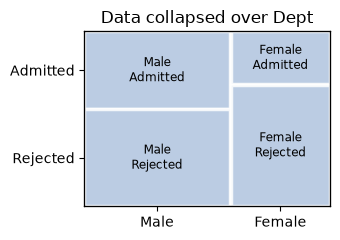

In [13]:
fig, ax = plt.subplots(figsize=(3.5, 2.5))
mosaic(tab_cdept.stack(), ax=ax,  properties=lambda k: {
        'facecolor': 'lightsteelblue',
        'alpha': 0.85,
        'edgecolor': 'white',
        'linewidth': 2.5,   # thicker separators
    })   
ax.invert_yaxis()
ax.set_title('Data collapsed over Dept')
plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'mosaic_collapsed.pdf')
# fig.savefig(fig_path, bbox_inches='tight') 

plt.show()

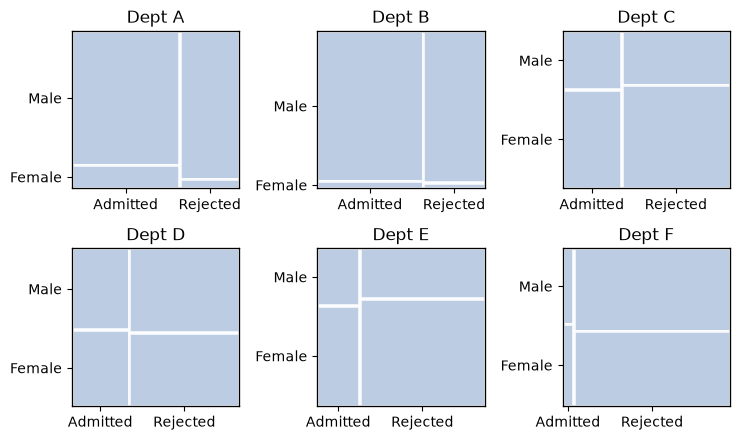

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), nrows=2, ncols=3) 

d = -1
Dept_levels = np.array(df['Dept'].cat.categories)

for i in range(2): 
    for j in range(3):
        d += 1 
        df_d = df.loc[df['Dept'] == Dept_levels[d]]
        tab_d = df_d.pivot(index=['Admit'], columns='Gender', values='Count').sort_index()
        mosaic(tab_d.stack(), ax=ax[i,j],  labelizer=lambda k: '', properties=lambda k: {
            'facecolor': 'lightsteelblue', 'alpha': 0.85, 'edgecolor': 'white', 'linewidth': 2}) 
        ax[i,j].invert_yaxis()
        ax[i,j].set_title(f'Dept {Dept_levels[d]}')


plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'mosaic_individual.pdf')
# fig.savefig(fig_path, bbox_inches='tight') 

plt.show()

In [15]:
# compute odds ratio for collapsed table
t_cdept = Table2x2(tb_cdept)
lo, hi = t_cdept.oddsratio_confint()
print(f'OR={t_cdept.oddsratio:.2f}, 95% CI=({lo:.2f}, {hi:.2f})')  

OR=1.84, 95% CI=(1.62, 2.09)


In [16]:
rows = []

# compute odds ratio and CI for each dept 
for d in range(6): 
   df_d = df.loc[df['Dept'] == Dept_levels[d]]
   tab_d = df_d.pivot(index=['Gender'], columns='Admit', values='Count').sort_index()
   tb_d = np.array(tab_d)

   # compute odds ratio manually
   # or_d = (tb_d[0,0] * tb_d[1,1]) / (tb_d[0,1] * tb_d[1,0])
   # print(or_d)

   # using Table2x2
   t_d = Table2x2(tb_d)
   or_d = t_d.oddsratio
   lo_d, hi_d = t_d.oddsratio_confint()  # 95% CI 
   rows.append({'Dept': Dept_levels[d], 'OR': or_d, 'lo': lo_d, 'hi': hi_d})
   print(f'OR={or_d:.2f}, 95% CI=({lo_d:.2f}, {hi_d:.2f})')


OR=0.35, 95% CI=(0.21, 0.58)
OR=0.80, 95% CI=(0.34, 1.89)
OR=1.13, 95% CI=(0.85, 1.50)
OR=0.92, 95% CI=(0.69, 1.24)
OR=1.22, 95% CI=(0.83, 1.81)
OR=0.83, 95% CI=(0.46, 1.51)


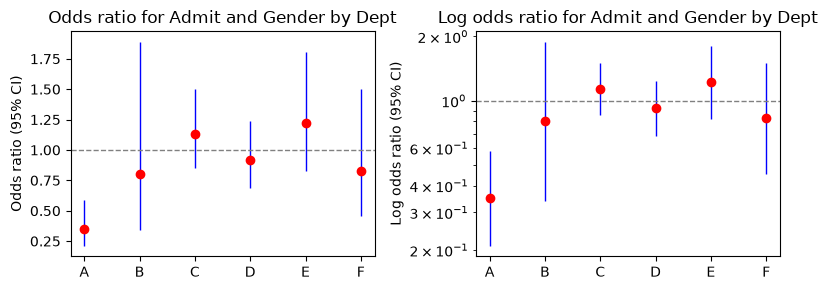

In [18]:
# Plot odds ratios
res = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3), nrows=1, ncols=2) 

x = np.arange(len(res))

def plot_or(a, log=False):
    a.vlines(x=x, ymin=res['lo'], ymax=res['hi'], color='blue', linewidth=1)
    a.plot(x, res['OR'], 'o', color='red')
    a.axhline(1, color='gray', linestyle='--', linewidth=1)
    a.set_xticks(x)
    a.set_xticklabels(res['Dept'], rotation=0)
    
    if log==True:
        a.set_yscale('log')          # optional, but recommended for ORs
        a.set_title('Log odds ratio for Admit and Gender by Dept')
        a.set_ylabel('Log odds ratio (95% CI)')
    else: 
        a.set_title('Odds ratio for Admit and Gender by Dept')
        a.set_ylabel('Odds ratio (95% CI)')

    a.margins(x=0.05)

plot_or(ax[0])
plot_or(ax[1], log=True)

plt.tight_layout()

# fig_path = os.path.join(fig_save_dir, 'oddsratios.pdf')
# fig.savefig(fig_path, bbox_inches='tight') 

plt.show()

In [19]:
# Fit full model
fmfull = glm(formula='Count ~ Admit*Gender*Dept', data=df, family=Poisson()).fit()
print(drop1_glm(fmfull))

                  Df      Deviance         AIC        LRT  Pr(>Chi)
<none>                1.825207e-13  207.059691                     
Admit:Gender:Dept  5  2.020428e+01  217.263967  20.204275  0.001144


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


In [20]:
# Fit minimal model 
fm = glm(formula='Count ~ Admit + Gender + Dept', data=df, family=Poisson()).fit()

# compute odds ratio by dept
df['fitted_fm'] = fm.fittedvalues
for d in range(6): 
    df_d = df.loc[df['Dept'] == Dept_levels[d]]
    tab_d = df_d.pivot(index=['Admit'], columns='Gender', values='fitted_fm').sort_index()
    tb_d = np.array(tab_d)
    t_d = Table2x2(tb_d)
    or_d = t_d.oddsratio
    print(or_d)

# Standardized Pearson residuals 
df['res_pearson_fm'] = fm.resid_pearson / np.sqrt(1-hat_diag(fm)) 
tab_fm_res = df.pivot(index=['Admit', 'Gender'], columns='Dept', values='res_pearson_fm').sort_index()
print(tab_fm_res.round(2))

1.0
0.9999999999999998
1.0000000000000002
1.0
1.0
1.0
Dept                 A      B      C     D      E      F
Admit    Gender                                         
Admitted Male    24.88  22.42  -7.73 -4.01  -8.40 -13.41
         Female  -5.52  -8.85   5.56  0.67   0.26  -9.51
Rejected Male    -1.97  -0.54  -9.63 -0.74  -6.75   7.55
         Female -17.40 -13.76  13.44  4.16  15.46  12.83


In [21]:
# collapse data over Gender
df_cgender = df.groupby(['Admit', 'Dept'], as_index=False)['Count'].sum()
tab_cgender = df_cgender.pivot(index=['Admit'], columns='Dept', values='Count').sort_index()
print(tab_cgender,'\n')

# compute proportions
print(tab_cgender / tab_cgender.sum(axis=0))

Dept        A    B    C    D    E    F
Admit                                 
Admitted  601  370  322  269  147   46
Rejected  332  215  596  523  437  668 

Dept             A         B         C         D         E         F
Admit                                                               
Admitted  0.644159  0.632479  0.350763  0.339646  0.251712  0.064426
Rejected  0.355841  0.367521  0.649237  0.660354  0.748288  0.935574


In [22]:
# collapse data over Admit
df_cadmit = df.groupby(['Gender', 'Dept'], as_index=False)['Count'].sum()
tab_cadmit = df_cadmit.pivot(index=['Gender'], columns='Dept', values='Count').sort_index()
print(tab_cadmit,'\n')

print(tab_cadmit / tab_cadmit.sum(axis=0))

Dept      A    B    C    D    E    F
Gender                              
Male    825  560  325  417  191  373
Female  108   25  593  375  393  341 

Dept           A         B         C         D         E         F
Gender                                                            
Male    0.884244  0.957265  0.354031  0.526515  0.327055  0.522409
Female  0.115756  0.042735  0.645969  0.473485  0.672945  0.477591


In [23]:
# Include interaction between Dept*Admit and Dept*Gender
fm1 = glm('Count ~ Dept*Admit + Dept*Gender', df, family=Poisson()).fit()

# compute odds ratio for each dept
df['fitted_fm1'] = fm1.fittedvalues 
for d in range(6): 
    df_d = df.loc[df['Dept'] == Dept_levels[d]]
    tab_d = df_d.pivot(index=['Admit'], columns='Gender', values='fitted_fm1').sort_index()
    t_d = Table2x2(np.array(tab_d))
    or_d = t_d.oddsratio
    print(or_d)

# Standardized Pearson residuals 
df['res_pearson_fm1'] = fm1.resid_pearson / np.sqrt(1-hat_diag(fm1)) 
tab_fm1_res = df.pivot(index=['Admit', 'Gender'], columns='Dept', values='res_pearson_fm1').sort_index()
print(tab_fm1_res.round(2))

0.9999999999999998
1.0000000000000002
1.0
1.0
1.000000000000001
1.0
Dept                A    B     C     D    E     F
Admit    Gender                                  
Admitted Male   -4.15 -0.5  0.87 -0.55  1.0 -0.62
         Female  4.15  0.5 -0.87  0.55 -1.0  0.62
Rejected Male    4.15  0.5 -0.87  0.55 -1.0  0.62
         Female -4.15 -0.5  0.87 -0.55  1.0 -0.62


In [24]:
# Define a new variable called DeptA
df['DeptA'] = (df['Dept'] == 'A').astype(int)
df['DeptA'] = pd.Categorical(df['DeptA'])
df['DeptA'].cat.categories

Index([0, 1], dtype='int64')

In [25]:
fm2 = update_glm(fm1, add='DeptA*Admit*Gender')

# compute odds ratio for each dept 
df['fitted_fm2'] = fm2.fittedvalues 
for d in range(6): 
    df_d = df.loc[df['Dept'] == Dept_levels[d]]
    tab_d = df_d.pivot(index=['Admit'], columns='Gender', values='fitted_fm2').sort_index()
    t_d = Table2x2(np.array(tab_d))
    print(f'OR={t_d.oddsratio:.2f}')

# Compare nested models
print(anova_nested(fm, fm1, fm2, fmfull))

# Goodness of fit test 
print(chi2.sf(fm2.deviance, fm2.df_resid))

OR=0.35
OR=1.03
OR=1.03
OR=1.03
OR=1.03
OR=1.03
         Resid. Df    Resid. Dev    Df     Deviance  Pr(>Chi)
Model 1       16.0  2.097671e+03   NaN          NaN       NaN
Model 2        6.0  2.173551e+01  10.0  2075.935706  0.000000
Model 3        4.0  2.556429e+00   2.0    19.179078  0.000068
Model 4        0.0  1.825207e-13   4.0     2.556429  0.634561
0.6345606792679137


c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


In [26]:
# Summary of fm2
print(fm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  Count   No. Observations:                   24
Model:                            GLM   Df Residuals:                        4
Model Family:                 Poisson   Df Model:                           19
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -80.808
Date:                Tue, 20 Oct 2026   Deviance:                       2.5564
Time:                        10:46:19   Pearson chi2:                     2.56
No. Iterations:                     6   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [27]:
# read accidents data again and fit logit model 
df = pd.read_csv('dataset/accidents.txt', sep=' ')

# convert G, S, L, I to categorical variables
cols_to_cat = ['G', 'L', 'S', 'I']
df[cols_to_cat] = df[cols_to_cat].astype('category')

# create a contingency table for df
tab_obs = df.pivot(index=['G', 'L', 'S'], columns='I', values='counts')
print(tab_obs, '\n')

I          N     Y
G L S             
F R N   3246   973
    Y   6134   757
  U N   7287   996
    Y  11587   759
M R N   6123  1084
    Y   6693   513
  U N  10381   812
    Y  10969   380 



In [28]:
# create a dataframe for fitting binomial obs
binom_df = tab_obs.rename(columns={'N': 'IN', 'Y': 'IY'}).reset_index()
print(binom_df)

# fit GLM 
fm_logit = glm(formula='IY + IN ~ G + L + S', data=binom_df, family=Binomial()).fit()
print(fm_logit.summary2())
print(fm_loglinear.summary2())

I  G  L  S     IN    IY
0  F  R  N   3246   973
1  F  R  Y   6134   757
2  F  U  N   7287   996
3  F  U  Y  11587   759
4  M  R  N   6123  1084
5  M  R  Y   6693   513
6  M  U  N  10381   812
7  M  U  Y  10969   380
             Results: Generalized linear model
Model:              GLM              Method:         IRLS   
Model Family:       Binomial         AIC:            82.1670
Link Function:      Logit            BIC:            82.4847
Dependent Variable: ['IY', 'IN']     Log-Likelihood: -37.083
Date:               2026-10-20 10:55 LL-Null:        -989.58
No. Observations:   8                Deviance:       7.4645 
Df Model:           3                Pearson chi2:   7.49   
Df Residuals:       4                Scale:          1.0000 
------------------------------------------------------------
             Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
------------------------------------------------------------
Intercept   -1.2164   0.0265 -45.9177 0.0000 -1.2683 -1.1645
G[T.M